# Hedging an option, step by step: delta with futures, gamma with options

Notebook 07 gave the greek signs. This one shows, with pictures, what a hedge does to a
position. One option, one Brent future, nothing else.

The rule ([docs/Options.md](../docs/Options.md)): **only the sign of the delta matters**.

| I have | Delta | To hedge the delta |
|---|---|---|
| Long call | always + | **sell** futures |
| Short put | always + | **sell** futures |
| Long put | always − | **buy** futures |
| Short call | always − | **buy** futures |

1. The delta of the four positions
2. What the futures hedge does to the P&L
3. Why the hedge has to be redone: gamma
4. Removing gamma: an option first, then futures
5. In real life: lots of 1,000 bbl

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Quote
from cmdty.instruments import VanillaOption
from cmdty.models.black76 import analytic_greeks, expected_payoff
from cmdty.plotting import MUTED, SERIES, titles, use_style

use_style()

today = ql.Date(25, 11, 2026)
F0, VOL = 75.0, 0.32
U, CONTRACT, EXPIRY = "BRENT", "2027-03", ql.Date(25, 2, 2027)  # 3 months


def market_at(f: float) -> MarketData:
    """Same market, only the Brent future price changes."""
    return MarketData(today=today, rate=0.04, quotes={U: Quote(f, VOL)})


def opt(kind: str, strike: float, qty: float) -> VanillaOption:
    """One vanilla option on the Brent future, qty in bbl, negative = sold."""
    return VanillaOption(underlying=U, contract=CONTRACT, expiry=EXPIRY, strike=strike,
                         option_type=kind, quantity=qty)


def value(o: VanillaOption, f: float) -> float:
    """Position value in $ (Black-76, QuantLib), at future price f."""
    return o.quantity * expected_payoff(o, market_at(f))


def greeks(o: VanillaOption, f: float) -> tuple[float, float]:
    """Position delta (bbl) and gamma (bbl per $), at future price f."""
    g = analytic_greeks(o, market_at(f))
    return o.quantity * g.delta, o.quantity * g.gamma


F = np.linspace(55, 100, 181)

Undiscounted values (the premium is paid at expiry here), so the numbers read directly as
"$ gained or lost". Strike 83 with the future at 75: an out-of-the-money call, delta about 0.3.

## 1. The delta of the four positions

Per barrel (quantity ±1). The dot is where the future is today (75 $).

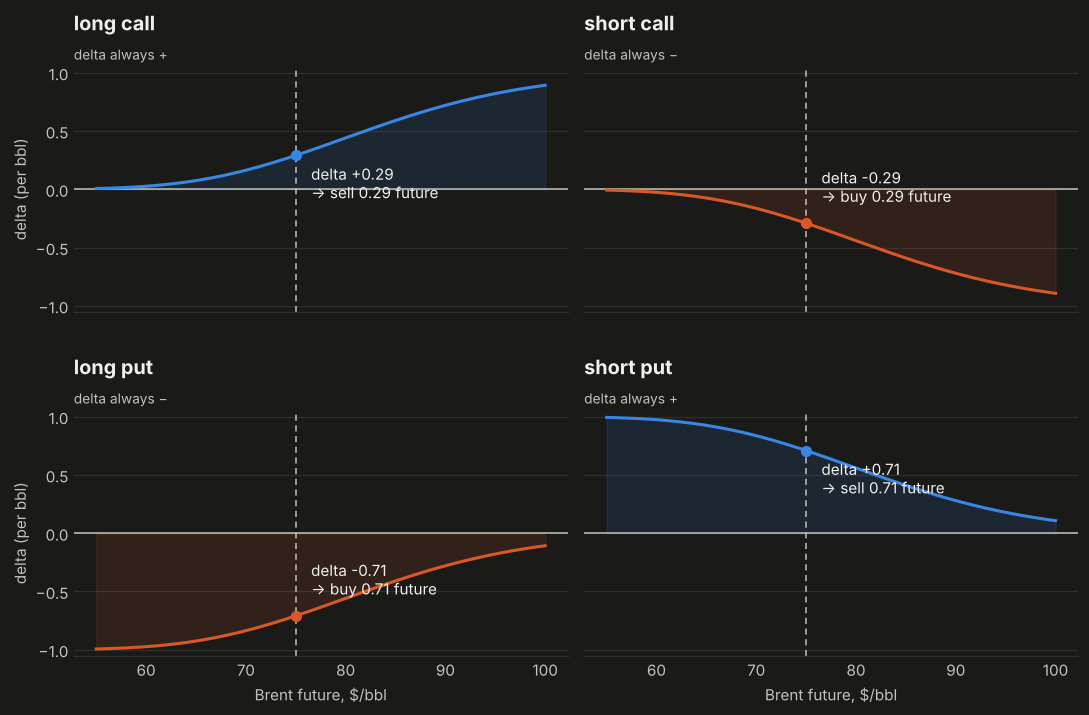

In [2]:
K = 83.0
positions = {
    "long call": ("call", +1), "short call": ("call", -1),
    "long put": ("put", +1), "short put": ("put", -1),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True, sharey=True)
for ax, (name, (kind, q)) in zip(axes.flat, positions.items()):
    o = opt(kind, K, q)
    d = [greeks(o, f)[0] for f in F]
    d0 = greeks(o, F0)[0]
    color = SERIES[0] if d0 > 0 else SERIES[1]
    ax.set_axisbelow(True)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.plot(F, d, color=color, linewidth=2)
    ax.fill_between(F, d, 0, color=color, alpha=0.12)
    ax.scatter([F0], [d0], color=color, zorder=3, s=40)
    hedge = "sell" if d0 > 0 else "buy"
    ax.annotate(f"delta {d0:+.2f}\n→ {hedge} {abs(d0):.2f} future", (F0, d0),
                xytext=(10, -28 if d0 > 0 else 14), textcoords="offset points", fontsize=10)
    ax.set(ylim=(-1.05, 1.05))
    titles(ax, name, "delta always + " if d0 > 0 else "delta always −")
for ax in axes[1]:
    ax.set(xlabel="Brent future, $/bbl")
for ax in axes[:, 0]:
    ax.set(ylabel="delta (per bbl)")
fig.tight_layout(h_pad=2.5)
plt.show()

- Blue (delta +): long call and short put. Hedge: **sell** futures.
- Orange (delta −): short call and long put. Hedge: **buy** futures.
- A single option never crosses zero: the long call stays between 0 and +1, the long put
  between −1 and 0.
- The hedge is **the same size, opposite sign**: 0.29 delta → 0.29 future. A future has a
  delta of 1, always.

## 2. What the futures hedge does to the P&L

Each position, plus its futures hedge, if the Brent moves right now. P&L in $/bbl.

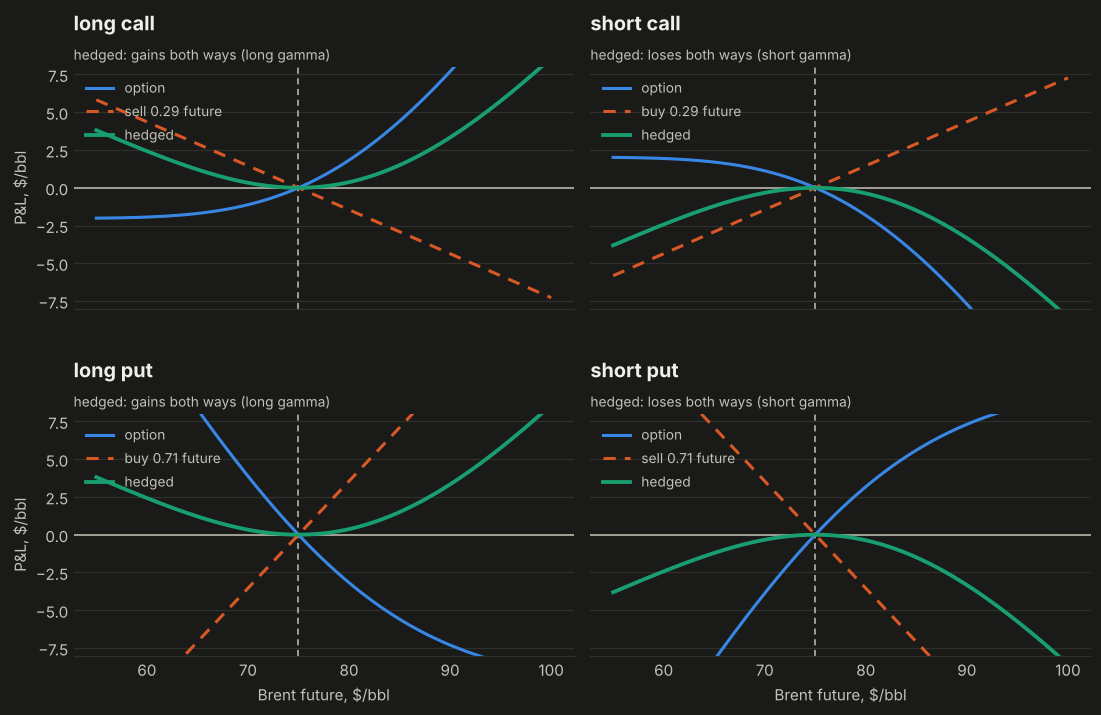

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True, sharey=True)
for ax, (name, (kind, q)) in zip(axes.flat, positions.items()):
    o = opt(kind, K, q)
    d0 = greeks(o, F0)[0]
    pnl_opt = np.array([value(o, f) - value(o, F0) for f in F])
    pnl_fut = -d0 * (F - F0)
    ax.set_axisbelow(True)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.plot(F, pnl_opt, color=SERIES[0], linewidth=2, label="option")
    ax.plot(F, pnl_fut, color=SERIES[1], linewidth=2, linestyle=(0, (4, 3)),
            label=f"{'sell' if d0 > 0 else 'buy'} {abs(d0):.2f} future")
    ax.plot(F, pnl_opt + pnl_fut, color=SERIES[2], linewidth=2.5, label="hedged")
    ax.set(ylim=(-8, 8))
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    titles(ax, name, "hedged: gains both ways (long gamma)" if q > 0
           else "hedged: loses both ways (short gamma)")
for ax in axes[1]:
    ax.set(xlabel="Brent future, $/bbl")
for ax in axes[:, 0]:
    ax.set(ylabel="P&L, $/bbl")
fig.tight_layout(h_pad=2.5)
plt.show()

- At 75 $ the green curve is **flat**: delta = 0, a small move does nothing.
- Further away it **curves**, because the future is a straight line and the option is not.
  That curve is the gamma.
- **Bought** options (top-left, bottom-left): the green curve goes **up** both ways, long gamma.
- **Sold** options: it goes **down** both ways, short gamma.
- Call or put does not matter for the gamma: only buying or selling.

## 3. Why the hedge has to be redone: gamma

Gamma = how much the delta moves when the future moves by 1 $. After a move the delta is not
0 any more, so the futures hedge is redone. The Brent goes 75 → 80 → 75 → 70 → 75, and at each
stop the hedge is reset to delta 0. 10,000 bbl of options.

In [4]:
SIZE = 10_000
path = [75.0, 80.0, 75.0, 70.0, 75.0]


def rehedge(o: VanillaOption) -> pd.DataFrame:
    """Reset the futures hedge to delta 0 at each stop of the path."""
    rows, futures, cash = [], 0.0, 0.0
    for f in path:
        d, g = greeks(o, f)
        trade = -d - futures  # futures to trade so that total delta = 0
        cash -= trade * f  # buying costs cash, selling brings cash
        futures += trade
        rows.append({"Brent": f, "option delta": d, "gamma": g,
                     "futures trade": trade, "futures held": futures})
    df = pd.DataFrame(rows)
    # futures P&L = cash from trades + value of what is still held
    df.attrs["futures P&L"] = cash + futures * path[-1]
    return df


long_call = opt("call", K, +SIZE)
short_call = opt("call", K, -SIZE)
lc, sc = rehedge(long_call), rehedge(short_call)
lc.round(0)

,Brent,option delta,gamma,futures trade,futures held
0,75.0,2910.0,285.0,-2910.0,-2910.0
1,80.0,4408.0,307.0,-1499.0,-4408.0
2,75.0,2910.0,285.0,1499.0,-2910.0
3,70.0,1635.0,219.0,1274.0,-1635.0
4,75.0,2910.0,285.0,-1274.0,-2910.0


Read the long call row by row:

- 75 → 80: the delta goes up (gamma > 0), the book is long again → **sell** futures, at 80.
- 80 → 75: the delta goes back down → **buy** them back, at 75.
- 75 → 70: delta down again → **buy** futures, at 70.
- 70 → 75: → **sell** them, at 75.

Sell high, buy low, every time. The Brent ends where it started, so the option is worth the
same: all the P&L comes from those re-hedges.

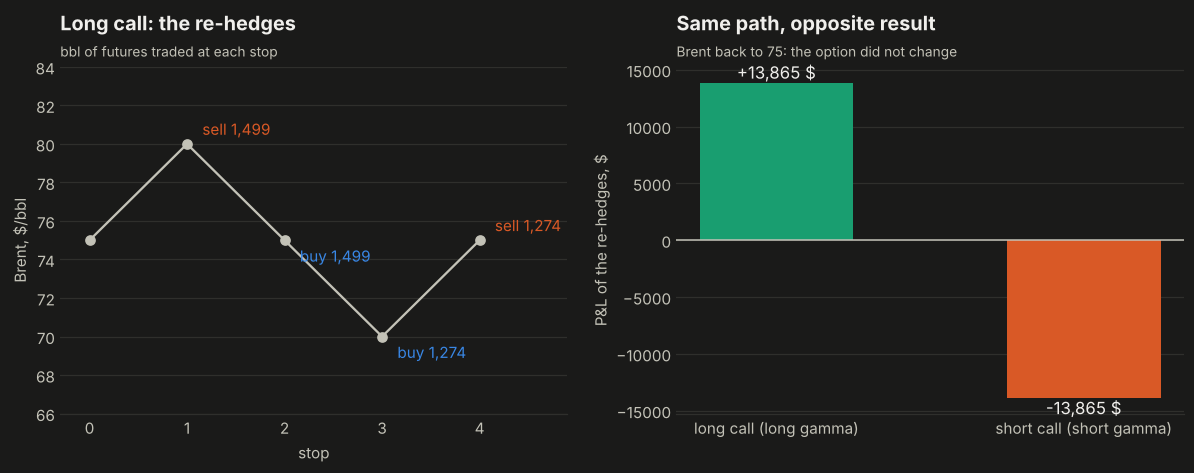

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.set_axisbelow(True)
ax.plot(range(len(path)), path, color=MUTED, linewidth=1.5, marker="o")
for i, row in lc.iterrows():
    if i == 0:
        continue
    side = "sell" if row["futures trade"] < 0 else "buy"
    color = SERIES[1] if side == "sell" else SERIES[0]
    ax.annotate(f"{side} {abs(row['futures trade']):,.0f}", (i, row["Brent"]),
                xytext=(10, 6 if side == "sell" else -14), textcoords="offset points",
                ha="left", fontsize=10, color=color)
ax.set(xticks=range(len(path)), xlabel="stop", ylabel="Brent, $/bbl", xlim=(-0.3, 4.9), ylim=(66, 84))
titles(ax, "Long call: the re-hedges", "bbl of futures traded at each stop")

ax = axes[1]
pnl = {"long call (long gamma)": lc.attrs["futures P&L"],
       "short call (short gamma)": sc.attrs["futures P&L"]}
ax.set_axisbelow(True)
ax.bar(list(pnl), list(pnl.values()), color=[SERIES[2], SERIES[1]], width=0.5)
ax.axhline(0, color=MUTED, linewidth=1)
for i, v in enumerate(pnl.values()):
    ax.text(i, v, f"{v:+,.0f} $", ha="center", va="bottom" if v > 0 else "top", fontsize=11)
ax.set(ylabel="P&L of the re-hedges, $")
titles(ax, "Same path, opposite result", "Brent back to 75: the option did not change")
plt.tight_layout()
plt.show()

- **Long gamma** re-hedges by selling high and buying low: it gains when the market moves.
- **Short gamma** does the opposite (buys high, sells low): it loses the same amount.
- Here no time passes. In real life, the long gamma position pays for this every day with its
  **theta** (the option loses value as time goes by). Long gamma wins if the market moves more
  than the theta it pays; short gamma wins if it moves less.

## 4. Removing gamma: an option first, then futures

To remove the gamma instead of re-hedging it, add the **opposite gamma**, which only an option
has. The long call (strike 83) is hedged with a sold call at the money (strike 75):

1. Sell enough of the 75 call to cancel the gamma.
2. That trade moves the delta too: reset it with futures.

In [6]:
call_83 = opt("call", K, +SIZE)
d1, g1 = greeks(call_83, F0)
_, g_unit = greeks(opt("call", 75.0, 1), F0)
call_75 = opt("call", 75.0, -g1 / g_unit)  # sold: gamma −g1
d2, g2 = greeks(call_75, F0)
fut = -(d1 + d2)

pd.DataFrame([
    ["start", "long call 83", d1, g1, d1, g1],
    ["1. gamma", "sell call 75", d2, g2, d1 + d2, g1 + g2],
    ["2. delta", "futures", fut, 0.0, d1 + d2 + fut, g1 + g2],
], columns=["step", "trade", "delta", "gamma", "total delta", "total gamma"]).round(1)

,step,trade,delta,gamma,total delta,total gamma
0,start,long call 83,2909.8,284.5,2909.8,284.5
1,1. gamma,sell call 75,-4586.8,-284.5,-1677.0,0.0
2,2. delta,futures,1677.0,0.0,0.0,0.0


Gamma goes to 0 in step 1, but the delta jumps from +2,900 to about −1,700 bbl: step 2 buys
futures. Never the other way round: a future has no gamma.

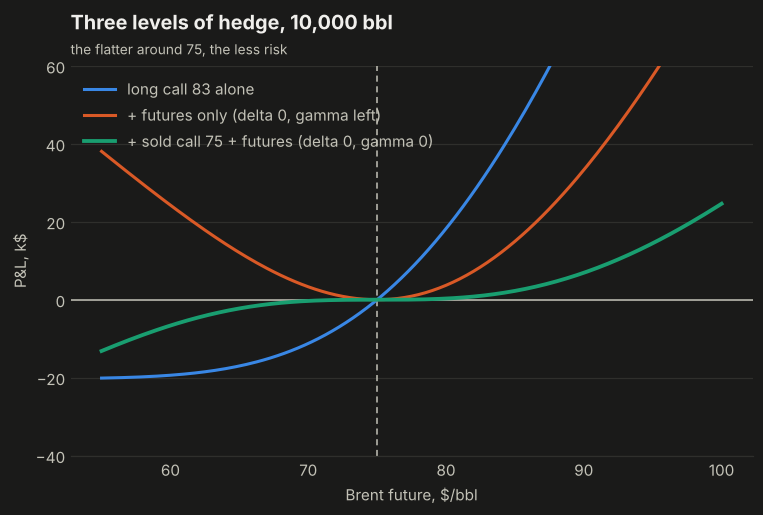

In [7]:
pnl_83 = np.array([value(call_83, f) - value(call_83, F0) for f in F])
pnl_75 = np.array([value(call_75, f) - value(call_75, F0) for f in F])

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.set_axisbelow(True)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.plot(F, pnl_83 / 1e3, color=SERIES[0], linewidth=2, label="long call 83 alone")
ax.plot(F, (pnl_83 - d1 * (F - F0)) / 1e3, color=SERIES[1], linewidth=2,
        label="+ futures only (delta 0, gamma left)")
ax.plot(F, (pnl_83 + pnl_75 + fut * (F - F0)) / 1e3, color=SERIES[2], linewidth=2.5,
        label="+ sold call 75 + futures (delta 0, gamma 0)")
ax.set(xlabel="Brent future, $/bbl", ylabel="P&L, k$", ylim=(-40, 60))
ax.legend(frameon=False, loc="upper left")
titles(ax, "Three levels of hedge, 10,000 bbl", "the flatter around 75, the less risk")
plt.show()

- Blue: no hedge, the P&L follows the Brent.
- Orange: futures only. Flat at 75, but it curves away: gamma.
- Green: option + futures. Flat over a much wider range. Far away it bends again: the gamma
  is 0 only at 75 (the two calls have different strikes), and a large move brings it back.

## 5. In real life: lots of 1,000 bbl

Futures and options on the Brent trade in lots of 1,000 bbl, so the hedge is rounded and a
small delta stays.

In [8]:
LOT = 1_000
pd.DataFrame([
    ["sell call 75 (gamma)", call_75.quantity, round(call_75.quantity / LOT)],
    ["futures (delta)", fut, round(fut / LOT)],
], columns=["trade", "exact, bbl", "lots"]).assign(
    **{"traded, bbl": lambda df: df["lots"] * LOT,
       "left over, bbl": lambda df: df["exact, bbl"] - df["lots"] * LOT}).round(0)

,trade,"exact, bbl",lots,"traded, bbl","left over, bbl"
0,sell call 75 (gamma),-8622.0,-9,-9000,378.0
1,futures (delta),1677.0,2,2000,-323.0


Never exactly 0: a few hundred bbl of delta stay, the rounding residual seen in notebook 06.
On a large book it hardly matters.

## Summary

| Greek | Hedged with | Why |
|---|---|---|
| Delta | **futures**, opposite sign | a future has delta 1 and nothing else |
| Gamma | **options**, opposite gamma (bought ↔ sold) | a future has no gamma |
| Order | gamma first, then delta | the option moves the delta, the future does not move the gamma |